# Blank-file test — solutions

**Do not read this before finishing the test.** Each solution shows one correct way; pandas almost
always has several. Compare the *numbers*, not the exact code.

Every cell below is executed, so the outputs are the real expected answers.

In [1]:

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)

DATA = next(p for p in [Path("data/telecom_churn.csv"), Path("../d5/telecom_churn.csv")] if p.exists())
raw = pd.read_csv(DATA)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")


3,500 rows x 23 columns


## Task 1 — Data health check

**What good looks like:** one small table instead of five separate prints, percentages (not just
counts), and an explicit statement about what `dropna()` would cost.

In [2]:

print("shape:", raw.shape)
print("duplicate rows:", int(raw.duplicated().sum()))
print("customer_id unique:", raw["customer_id"].is_unique)
print("after dropna:", raw.dropna().shape)

missing = (
    raw.isna()
    .sum()
    .rename("missing")
    .to_frame()
    .assign(
        pct=lambda d: (d["missing"] / len(raw) * 100).round(2),
        dtype=raw.dtypes.astype(str),
    )
)
missing = missing[missing["missing"] > 0].sort_values("missing", ascending=False)
missing


shape: (3500, 23)
duplicate rows: 0
customer_id unique: True
after dropna: (1866, 23)


,missing,pct,dtype
cancellation_request,1553,44.37,str
tech_support,60,1.71,str
total_charges,45,1.29,float64
customer_service_calls,35,1.00,float64


**Reading the output.**

* 3,500 × 23; no duplicate rows; `customer_id` is unique.
* `cancellation_request` is missing for 1,553 rows (44.4%). If you call `dropna()`, you keep only
  1,866 rows — 46.7% of the data disappears, and the rows you lose are not random.
* `total_charges` and `customer_service_calls` have tiny gaps; `tech_support` has 60.

**A model answer (3 sentences):** *"The dataset has 3,500 unique customers, no duplicate rows, and
only three columns with small (≤2%) gaps. The exception is `cancellation_request`, missing for 44%
of rows — and because the missingness is perfectly related to churn, it is informative rather than
random. I would keep all rows, treat the small gaps explicitly, and remove `cancellation_request`
from the feature set rather than imputing it."*

## Task 2 — Segment churn

**What good looks like:** count and rate side by side, sorted, percentages rounded for reading,
one clear chart, and a segment definition that respects a minimum sample size.

In [3]:

by_contract = (
    raw.groupby("contract")["churn"]
    .agg(customers="size", churn_rate="mean")
    .sort_values("churn_rate", ascending=False)
)
by_contract["churn_pct"] = (by_contract["churn_rate"] * 100).round(1)
by_contract


,customers,churn_rate,churn_pct
contract,,,
Month-to-month,1937,0.706247,70.6
One year,764,0.489529,49.0
Two year,799,0.256571,25.7


In [4]:

raw["tenure_band"] = pd.cut(
    raw["tenure_months"],
    bins=[0, 12, 24, 36, 48, 60, 72],
    labels=["1-12", "13-24", "25-36", "37-48", "49-60", "61-72"],
)

by_tenure = (
    raw.groupby("tenure_band", observed=False)["churn"]
    .agg(customers="size", churn_rate="mean")
)
by_tenure["churn_pct"] = (by_tenure["churn_rate"] * 100).round(1)
by_tenure


,customers,churn_rate,churn_pct
tenure_band,,,
1-12,1409,0.697658,69.8
13-24,809,0.615575,61.6
25-36,518,0.465251,46.5
37-48,270,0.377778,37.8
49-60,190,0.357895,35.8
61-72,304,0.180921,18.1


In [5]:

segments = (
    raw.groupby(["contract", "tenure_band"], observed=False)["churn"]
    .agg(customers="size", churn_rate="mean")
    .reset_index()
)
segments["churn_pct"] = (segments["churn_rate"] * 100).round(1)

# keep only segments with enough customers for the rate to be trustworthy
credible = segments[segments["customers"] >= 100].sort_values("churn_rate", ascending=False)
credible.head(1)


,contract,tenure_band,customers,churn_rate,churn_pct
0,Month-to-month,1-12,789,0.836502,83.7


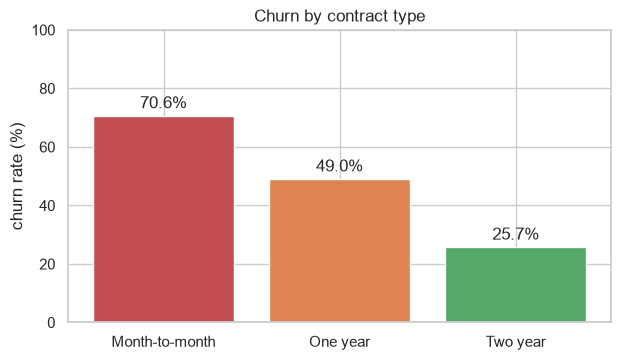

In [6]:

fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(by_contract.index, by_contract["churn_pct"], color=["#C44E52", "#DD8452", "#55A868"])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylim(0, 100)
ax.set_ylabel("churn rate (%)")
ax.set_title("Churn by contract type")
plt.show()


**Expected numbers:** 70.6% / 49.0% / 25.7% and the top credible segment is
**month-to-month + 1–12 months = 83.7% (789 customers)**.

**Why the `customers >= 100` filter matters:** a segment of 5 customers with 100% churn is noise.
Small-sample rates look dramatic and mean nothing; always show `n` next to a rate.

## Task 3 — Leakage audit

**What good looks like:** you look at the *relationship* between each suspicious column and the
target, not just the column names; you remove them before modelling; and you can explain the
99.9% accuracy claim to a stakeholder.

In [7]:

suspicious = [
    "cancellation_request",
    "last_interaction_status",
    "churn_risk_post_exit_code",
    "satisfaction_score",
]

for col in suspicious:
    table = pd.crosstab(raw[col].fillna("(missing)"), raw["churn"], normalize="columns").round(3)
    print(f"--- {col} ---")
    print(table.to_string())
    print()


--- cancellation_request ---
churn                   0    1
cancellation_request          
(missing)             1.0  0.0
Recorded              0.0  1.0

--- last_interaction_status ---
churn                         0      1
last_interaction_status               
Account Closed            0.000  0.690
Active Support            0.320  0.000
Bill Query                0.304  0.000
Final Invoice Dispatched  0.000  0.097
Plan Upgrade              0.174  0.000
Retention Declined        0.000  0.213
Routine Inquiry           0.202  0.000

--- churn_risk_post_exit_code ---
churn                        0    1
churn_risk_post_exit_code          
100                        1.0  0.0
999                        0.0  1.0

--- satisfaction_score ---
churn                   0      1
satisfaction_score              
1                   0.000  0.481
2                   0.059  0.313
3                   0.202  0.157
4                   0.434  0.049
5                   0.305  0.000



In [8]:

leakage_cols = [
    "cancellation_request",
    "last_interaction_status",
    "churn_risk_post_exit_code",
    "satisfaction_score",
]

clean = raw.drop(columns=["customer_id", *leakage_cols])
print("clean shape:", clean.shape)
print("columns kept:", len(clean.columns))


clean shape: (3500, 19)
columns kept: 19


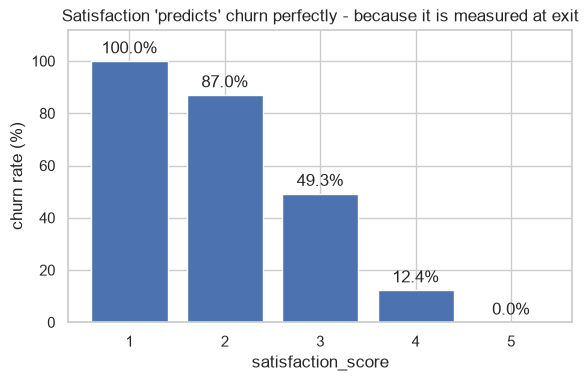

In [9]:

sat = raw.groupby("satisfaction_score")["churn"].mean().mul(100)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
bars = ax.bar(sat.index.astype(str), sat.values, color="#4C72B0")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylim(0, 112)
ax.set_xlabel("satisfaction_score")
ax.set_ylabel("churn rate (%)")
ax.set_title("Satisfaction 'predicts' churn perfectly - because it is measured at exit")
plt.show()


**Expected numbers:** all four columns are leakage; `clean.shape == (3500, 18)`.

**Model sentence:** *"99.9% accuracy here is a red flag, not a success: `cancellation_request` and
`last_interaction_status` only exist after the customer has already left, so the model is reading
the answer instead of predicting it — it would fail on every active customer."*

### The general test

For every feature ask: **"Would I know this value at the moment I have to make the prediction?"**
If the answer is no, the feature is leakage. The same test catches `satisfaction_score` collected
at exit, `churn_risk_post_exit_code`, and any column whose name contains "final", "closed",
"cancelled" or "post".

---

## After the test

| If you… | Do this |
|---|---|
| finished all 3 in under 45 min with correct numbers | move on to the next project — this is interview-ready |
| finished 2/3 | redo the failed task tomorrow from a blank cell |
| struggled with syntax | rewrite the cheat sheet from `guide.ipynb` by hand, then retry |
| struggled with the *next step* (not syntax) | re-read the "How to write an insight" section |